# 3. Root finding

**Pin number**: 239

### Assigning parameters and defining the function $f(x)$

**Question 1.** Assign values to variables PIN, $k$, $N$, $a$, $b$ and $\Delta x$. Define the function $f(x)=\exp(x)-\frac{2kx^2}{2+x^2}$. 

In [74]:
import numpy as np

PIN = 239
k = 7.5 - (239/120)
N = 64
a = -3.0
b = 3.0
Delta_x = (b-a)/N

def f(x):
    value = np.exp(x) - (2 * k * x**2)/(2 + x**2)
    return value


**Question 2.** Produce a plot of $f(x)$ for $a\leq x\leq b$. Provide appropriate axis labels and plot title as well as add gridlines to the plot. By looking at the graph, estimate the values of $x$ for which $f(x)=0$, i.e., the roots of $f(x)$ and record them by editing the appropriate cell of the JupyterLab worksheet.

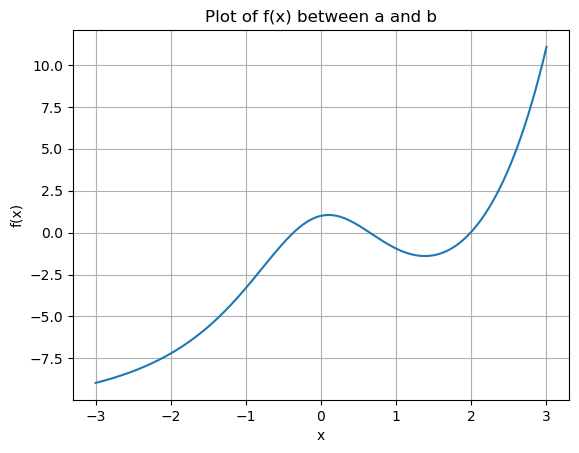

In [75]:
import matplotlib.pyplot as plt

x_values = np.linspace(a, b, 500)
y_values = f(x_values)
plt.plot(x_values, y_values)
plt.xlabel('x')
plt.ylabel('f(x)')
plt.title('Plot of f(x) between a and b')
plt.grid()
plt.show()


Estimated values of roots of $f(x)$ from the graph are: -0.40, 0.70 and 2.00

### Bisection method

**Question 3.** Write a code to find a root of $f(x)$ by means of the Bisection method with starting values $A_0=-3.0$ and $B_0=3.0$ in 20 iterations. Tabulate your results in a table with the following 7 columns: $i$, $A_i$, $C_i$, $B_i$, $f(A_i)$, $f(C_i)$, $f(B_i)$. Provide appropriate header names to the columns.

In [76]:
from tabulate import tabulate

A = a
B = b

i_BS = []
A_BS = []
B_BS = []
C_BS = []
fA_BS = []
fB_BS = []
fC_BS = []

for i in range(20):
    C = (A + B)/2
    fA = f(A)
    fB = f(B)
    fC = f(C)

    i_BS.append(i)
    A_BS.append(A)
    B_BS.append(B)
    C_BS.append(C)
    fA_BS.append(fA)
    fB_BS.append(fB)
    fC_BS.append(fC)

    if fA * fC < 0:
        B = C
    else:
        A = C


tab=[]
for k in range(20):
    tab+=[[i_BS[k],A_BS[k],C_BS[k],B_BS[k],fA_BS[k],fC_BS[k],fB_BS[k]]]

col_names = ["i","A_i","C_i","B_i","f(A_i)","f(C_i)","f(B_i)"]

print(tabulate(tab, headers=col_names))
    

  i        A_i        C_i        B_i        f(A_i)        f(C_i)        f(B_i)
---  ---------  ---------  ---------  ------------  ------------  ------------
  0  -3          0          3         -8.96385       1            11.0719
  1  -3         -1.5        0         -8.96385      -5.60922       1
  2  -1.5       -0.75       0         -5.60922      -1.94593       1
  3  -0.75      -0.375      0         -1.94593      -0.0364333     1
  4  -0.375     -0.1875     0         -0.0364333     0.638722      1
  5  -0.375     -0.28125   -0.1875    -0.0364333     0.335699      0.638722
  6  -0.375     -0.328125  -0.28125   -0.0364333     0.157508      0.335699
  7  -0.375     -0.351562  -0.328125  -0.0364333     0.0624029     0.157508
  8  -0.375     -0.363281  -0.351562  -0.0364333     0.0134379     0.0624029
  9  -0.375     -0.369141  -0.363281  -0.0364333    -0.0113861     0.0134379
 10  -0.369141  -0.366211  -0.363281  -0.0113861     0.00105397    0.0134379
 11  -0.369141  -0.367676  -0.366

**Question 4.**  Assume that $C_{20}$ is the true value for a root of $f(x)$. Calculate the absolute value of the error $|C_i-C_{20}|$ for $i\leq 19$ and $\ln|C_i-C_{20}|$. Store your results in appropriate lists (see manual). Create a plot of $\ln|C_i-C_{20}|$ against $i$ with appropriate axis labels and plot title.

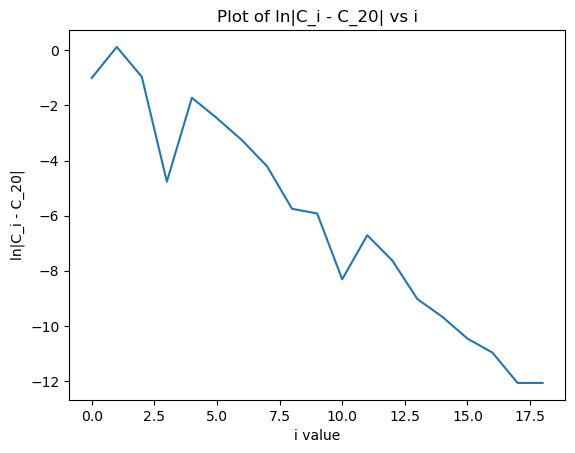

In [77]:
errorBM = []
for i in range(19):
    value = abs(C_BS[19] - C_BS[i])
    errorBM.append(value)
    
ln_errorBM = np.log(errorBM)
plt.plot(i_BS[:-1], ln_errorBM)
plt.xlabel("i value")
plt.ylabel("ln|C_i - C_20|")
plt.title("Plot of ln|C_i - C_20| vs i")
plt.show()

### Newton-Raphson method

**Question 5.** Define the function $f'(x)=\exp(x)-\frac{8 k x}{(2 + x^2)^2}$. 

Using the starting value $A_0=-3.0$, implement 20 iterations of the Newton-Raphson method. Repeat the Newton-Raphson method for a different starting value $B_0=3.0$.

Assume that $A_{20}$ is the true value of a root of $f(x)$. For $i\leq 20$, calculate the $|A_i-A_{20}|$ and $|B_i-B_{20}|$. Store your results in appropriate lists (see manual).

Tabulate your results in a table with 7 columns: $i$, $A_i$, $|A_i-A_{20}|$, $f(A_i)$, $B_i$, $|B_i-B_{20}|$, $f(B_i)$. Provide appropriate column headers.

After producing a table and looking at the columns containing $|A_i-A_{20}|$ and $|B_i-B_{20}|$, re-edit your computation cell by defining two more lists that store $\ln|A_i-A_{20}|$ and $\ln|B_i-B_{20}|$. Decide on the appropriate range of $i$ in each case.

In [78]:
def f_der(x):
    value = np.exp(x) - (8*k*x)/(2 + x**2)**2
    return value


A = a
B = b

i_NR = []
A_NR = []
fA_NR = []
B_NR = []
fB_NR = []


for i in range(20):
    i_NR.append(i)
    A_NR.append(A)
    fA_NR.append(f(A))
    B_NR.append(B)
    fB_NR.append(f(B))

    A += -(f(A)/f_der(A))
    B += -(f(B)/f_der(B))

errorNR_A = []
errorNR_B = []
for i in range(19):
    valueA = abs(A - A_NR[i])
    valueB = abs(B - B_NR[i])
    errorNR_A.append(valueA)
    errorNR_B.append(valueB)
ln_errorNR_A = np.log(errorNR_A)
ln_errorNR_B = np.log(errorNR_B)







tab=[]
for k in range(19):
    tab+=[[i_NR[k],A_NR[k],errorNR_A[k],fA_NR[k],B_NR[k],errorNR_B[k],fB_NR[k]]]

col_names = ["i","A_i","ln|A-A_i|","f(A_i)","B_i","ln|B-B_i|","f(B_i)"]

print(tabulate(tab, headers=col_names))


  i       A_i    ln|A-A_i|         f(A_i)      B_i    ln|B-B_i|         f(B_i)
---  --------  -----------  -------------  -------  -----------  -------------
  0  -3        6.48516      -31.0411       3        0.485158     -11.0054
  1   5.12939  1.64423      133.599        3.67448  0.189317       6.33063
  2   4.33388  0.848726      41.8967       3.50386  0.0186976      0.566624
  3   3.77313  0.287969      10.1967       3.48536  0.000198973    0.00596599
  4   3.52647  0.0413159      1.26846      3.48516  2.27615e-08    6.82399e-07
  5   3.48612  0.000959785    0.0287907    3.48516  4.44089e-16    1.42109e-14
  6   3.48516  5.29391e-07    1.58714e-05  3.48516  0              0
  7   3.48516  1.61204e-13    4.83169e-12  3.48516  0              0
  8   3.48516  0              0            3.48516  0              0
  9   3.48516  0              0            3.48516  0              0
 10   3.48516  0              0            3.48516  0              0
 11   3.48516  0              0     

/var/folders/dj/901mwm8s23x_zlv1zxqm8yd80000gn/T/ipykernel_21259/1040913235.py:33: RuntimeWarning: divide by zero encountered in log
  ln_errorNR_A = np.log(errorNR_A)
/var/folders/dj/901mwm8s23x_zlv1zxqm8yd80000gn/T/ipykernel_21259/1040913235.py:34: RuntimeWarning: divide by zero encountered in log
  ln_errorNR_B = np.log(errorNR_B)


### Linear interpolation method

**Question 6.** Implement the Linear interpolation method with starting values $A_0=-3.0$ and $B_0=3.0$ for the first 20 iterations (i.e., $i\leq 20$).

Assume that $C_{20}$ is a true root of $f(x)$. Calculate $|C_i-C_{20}|$ for $i\leq 20$ and store your results in a appropriate list (see manual). 

Tabulate your results in a table with 7 columns: $i$, $A_i$, $C_i$, $B_i$, $f(A_i)$, $f(C_i)$, $f(B_i)$. Provide appropriate header names to the columns. 

After inspecting the values $f(C_i)$ in your table, calculate the values $\ln|C_i-C_{20}|$ for an appropriate range of $i$. Store your results in a appropriate list (see manual).

In [79]:
# Use this cell to implement the Linear interpolation method and other tasks of Question 6.

A = a
B = b

i_LI = []
A_LI = []
B_LI = []
C_LI = []
fA_LI = []
fB_LI = []
fC_LI = []

for i in range(20):
    fA = f(A)
    fB = f(B)
    C = A - ((B - A)*fA)/(fB-fA)
    fC = f(C)
    
    i_LI.append(i)
    A_LI.append(A)
    B_LI.append(B)
    C_LI.append(C)
    fA_LI.append(fA)
    fB_LI.append(fB)
    fC_LI.append(fC)

    if fC * fA <= 0:
        B = C
    else:
        A = C

errorLI = []
for i in range(19):
    valueC = abs(C - C_LI[i])
    errorLI.append(valueC)
ln_errorLI = np.log(errorLI)


tab=[]
for k in range(20):
    tab+=[[i_LI[k],A_LI[k],C_LI[k],B_LI[k],fA_LI[k],fC_LI[k],fB_LI[k]]]

col_names = ["i","A_i","C_i","B_i","f(A_i)","f(C_i)","f(B_i)"]

print(tabulate(tab, headers=col_names))




  i        A_i        C_i      B_i      f(A_i)      f(C_i)     f(B_i)
---  ---------  ---------  -------  ----------  ----------  ---------
  0  -3          5.80569   3        -29.4048    298.2        -9.36901
  1  -3         -2.20963   5.80569  -29.4048    -25.4289    298.2
  2  -2.20963   -1.57983   5.80569  -25.4289    -19.7793    298.2
  3  -1.57983   -1.12043   5.80569  -19.7793    -13.5565    298.2
  4  -1.12043   -0.819253  5.80569  -13.5565     -8.60481   298.2
  5  -0.819253  -0.633446  5.80569   -8.60481    -5.4849    298.2
  6  -0.633446  -0.517148  5.80569   -5.4849     -3.64993   298.2
  7  -0.517148  -0.440693  5.80569   -3.64993    -2.54278   298.2
  8  -0.440693  -0.38788   5.80569   -2.54278    -1.84015   298.2
  9  -0.38788   -0.349894  5.80569   -1.84015    -1.37179   298.2
 10  -0.349894  -0.321707  5.80569   -1.37179    -1.04635   298.2
 11  -0.321707  -0.300282  5.80569   -1.04635    -0.812417  298.2
 12  -0.300282  -0.283692  5.80569   -0.812417   -0.63962   298.

### Secant method

**Question 7.** Implement the Secant method with the starting values $A_0=-3.0$ and $A_1=3.0$ for the first 20 iterations (see manual for further instructions).

Assume that $A_{20}$ is a true root of $f(x)$. Calculate $|A_i-A_{20}|$ for $i\leq 20$ and store your results in an appropriate list (see manual). 

Tabulate your results in a table with 4 columns: $i$, $A_i$, $|A_i-A_{20}|$, $f(A_i)$. Provide appropriate header names to the columns.

After inspecting the values $|A_i-A_{20}|$ in your table, create another list (see manual) and store in that list the values $\ln|A_i-A_{20}|$ for an appropriate range of $i$.

In [80]:
# Use this cell to implement the Secant method and other tasks of Question 7.

i_SM = []
A_SM = [-3, 3]
fA_SM = [f(-3), f(3)]

for i in range(1, 21):
    val2 = A_SM[i]
    val1 = A_SM[i-1]

    f_val2 = f(val2)
    f_val1 = f(val1)

    diff = (f_val2 - f_val1)
    if abs(diff) > (10**-30):
        v = (val2 - val1)*f_val2
        value = val2 - (v)/(diff)
    else:
        value = val2

    i_SM.append(i)
    A_SM.append(value)
    fA_SM.append(f(value))

print(i_SM)
print(A_SM)

errorSM = []
for i in range(19):
    valueC = abs(A_SM[20] - A_SM[i])
    errorSM.append(valueC)
ln_errorSM = np.log(errorSM)

tab=[]
for k in range(19):
    tab+=[[i_SM[k],A_SM[k],errorSM[k],fA_SM[k]]]

col_names = ["i","A_i","C_i","B_i","f(A_i)","f(C_i)","f(B_i)"]

print(tabulate(tab, headers=col_names))


[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]
[-3, 3, np.float64(6.29572057371458), np.float64(3.0701454933533867), np.float64(3.1314421665100416), np.float64(3.593688632597712), np.float64(3.4615792715448617), np.float64(3.4837205644496168), np.float64(3.4851775749996627), np.float64(3.4851579364770964), np.float64(3.485157952700659), np.float64(3.4851579527008423), np.float64(3.485157952700842), np.float64(3.485157952700842), np.float64(3.485157952700842), np.float64(3.485157952700842), np.float64(3.485157952700842), np.float64(3.485157952700842), np.float64(3.485157952700842), np.float64(3.485157952700842), np.float64(3.485157952700842), np.float64(3.485157952700842)]
  i       A_i          C_i            B_i
---  --------  -----------  -------------
  1  -3        6.48516      -31.0411
  2   3        0.485158     -11.0054
  3   6.29572  2.81056      506.072
  4   3.07015  0.415012      -9.80335
  5   3.13144  0.353716      -8.65557
  6   3.59369  0.108531 

/var/folders/dj/901mwm8s23x_zlv1zxqm8yd80000gn/T/ipykernel_21259/191848673.py:32: RuntimeWarning: divide by zero encountered in log
  ln_errorSM = np.log(errorSM)


**Question 8.** Create a scatter plot showing the previously calculated lists storing the natural logarithms of the absolute values of errors against the index $i$ for four root-finding methods (see manual for further instructions). Provide appropriate axis labels and plot title as well as create a legend for your data. Discuss very briefly (3-4 sentences) the convergence behaviour that you observe for different methods in the specifically provided cell in the JupyterLab notebook.

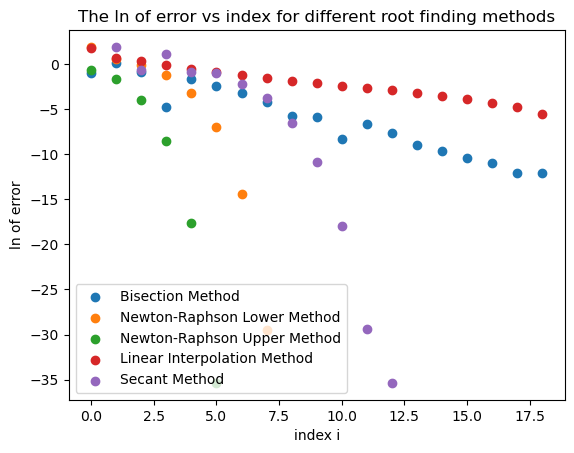

In [81]:
# Use this cell to create a plot of ln|error| against i for all four root-finding methods 

plt.scatter(i_BS[:-1], ln_errorBM,label="Bisection Method")
plt.scatter(i_NR[:-1], ln_errorNR_A,label="Newton-Raphson Lower Method")
plt.scatter(i_NR[:-1], ln_errorNR_B,label="Newton-Raphson Upper Method")
plt.scatter(i_LI[:-1], ln_errorLI,label="Linear Interpolation Method")
plt.scatter(i_SM[:-1], ln_errorSM,label="Secant Method")

plt.xlabel("index i")
plt.ylabel("ln of error")
plt.title("The ln of error vs index for different root finding methods")
plt.legend(loc='lower left')
plt.show()

Brief comments on the observed convergence behaviour for different methods:

The Newton-Raphson Method using the upper initial value converges the fastest and reaches a constant value after about 5 iterations, then the second fastest is the Newton-Raphson Method using the lower initial value. This suggests that Newton-Raphson method converges the fastest out of all of the methids tested. Then the next fastest to converge is Secant Method after 11 iterations. followed by Bisection and Linear Interpolation which haven't yet fully converged after all iterations.